# 3. Optimizer study

Model B is trained three times: with plain SGD, with SGD and momentum 0.9, and with Adam. The runs
are compared on convergence speed and on final accuracy. Adam is the optimizer used for Model B in
the rest of the study.

- **Learning rates.** Adam's steps are normalised per parameter, so it uses 0.001. SGD steps in
  proportion to the raw gradient and gets 0.01; at 0.001 it would be unfairly slow. Both SGD runs
  use the same rate, so only the momentum term differs between them.
- **Why Adam for Model B.** A depthwise kernel holds 9 weights while a pointwise kernel holds
  hundreds, so their gradients differ in scale by orders of magnitude. A single global SGD learning
  rate cannot suit both; Adam adapts the step size of every parameter.

**Run time:** about 6 minutes per run on an NVIDIA T4 GPU, about 20 minutes in all. A CPU takes
hours.

**Writes:** for each run (`model_b_sgd`, `model_b_sgd_momentum`, `model_b_adam`):
`results/<run>/history.json`, `test_metrics.json` and `curves.png`, and `checkpoints/<run>/best.pt`.
Also `results/figures/optimizer_overlay.png` and `results/model_b_adam/confusion_matrix.png`.

## Setup

Folders, the random seed, the device, and small helpers for files and figures. Every notebook in
this folder starts with the same setup.

In [1]:
import json
import os
import platform
import random
import re
import subprocess
import sys
from pathlib import Path

import numpy as np
import torch
import torchvision

# Everything is read from and written to folders next to this notebook.
DATA_DIR = Path("data")                # the downloaded dataset and a decoded-pixel cache
RESULTS_DIR = Path("results")          # metrics, figures and tables
CHECKPOINT_DIR = Path("checkpoints")   # trained weights

SEED = 42            # fixes the split, the initial weights, augmentation and batch order
NUM_CLASSES = 10     # EuroSAT land-cover classes
INPUT_SHAPE = (3, 64, 64)

# cuBLAS needs this workspace setting for repeatable matrix products on a GPU.
CUBLAS_WORKSPACE = ":4096:8"


def seed_everything(seed, deterministic=True):
    """Seed Python, NumPy and PyTorch, so a run gives the same numbers every time.

    With ``deterministic=True``, cuDNN uses deterministic algorithms and stops
    auto-tuning, and PyTorch prefers deterministic implementations. This costs a
    little speed. Without it, two runs of the same experiment can differ by a few
    tenths of a percent, the same size as some differences between the models.
    A few GPU operations have no deterministic version; PyTorch then warns
    instead of stopping.
    """
    if deterministic:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", CUBLAS_WORKSPACE)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)  # seeds the CPU and every GPU
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic
    torch.use_deterministic_algorithms(deterministic, warn_only=True)


def cpu_name():
    """The processor's model name, or an empty string if the operating system won't say."""
    name = ""
    try:
        if sys.platform == "win32":
            import winreg

            key = winreg.OpenKey(
                winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0"
            )
            name = str(winreg.QueryValueEx(key, "ProcessorNameString")[0])
        elif sys.platform.startswith("linux"):
            with open("/proc/cpuinfo", encoding="utf-8") as handle:
                for line in handle:
                    if line.lower().startswith("model name"):
                        name = line.split(":", 1)[1]
                        break
        elif sys.platform == "darwin":
            name = subprocess.run(
                ["sysctl", "-n", "machdep.cpu.brand_string"],
                capture_output=True, text=True, timeout=5, check=False,
            ).stdout
    except Exception:
        name = ""
    name = name or platform.processor() or ""
    name = re.sub(r"\((R|TM|C)\)", "", name, flags=re.IGNORECASE)  # trademark signs
    return " ".join(name.split())


def describe_device(device):
    """A readable name for a device, such as ``cuda:0 (Tesla T4)``.

    Every timing is recorded together with this name: a time means little
    without the hardware it was measured on.
    """
    device = torch.device(device)
    if device.type == "cuda":
        index = device.index if device.index is not None else torch.cuda.current_device()
        return f"cuda:{index} ({torch.cuda.get_device_name(index)})"
    name = cpu_name()
    return f"cpu ({name})" if name else "cpu"


#: Model name -> function building it; filled in by the model definitions below.
MODEL_BUILDERS = {}


def build_model(name, num_classes=NUM_CLASSES):
    """Seed PyTorch, then build ``name``: the same seed always gives the same initial weights.

    The three optimizer runs rely on this to start from identical weights, so
    that their comparison measures the optimizer and not the initialisation.
    """
    torch.manual_seed(SEED)
    return MODEL_BUILDERS[name](num_classes)


def count_parameters(model, trainable_only=True):
    """Number of parameters; frozen ones are left out when ``trainable_only``."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def model_size_kb(model):
    """Size of the saved weights (``state_dict``) in KB, where 1 KB = 1,024 bytes.

    Saving the weights, as a device would store them, rather than counting 4
    bytes per parameter, also counts buffers such as batch-norm statistics.
    """
    import io

    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / 1024


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python       {platform.python_version()} ({platform.system()})")
print(f"PyTorch      {torch.__version__}")
print(f"torchvision  {torchvision.__version__}")
print(f"NumPy        {np.__version__}")
print(f"Device       {describe_device(DEVICE)}")

Python       3.13.15 (Linux)
PyTorch      2.11.0+cu130
torchvision  0.26.0+cu130
NumPy        2.1.3
Device       cuda:0 (Tesla T4)


Figures are shown inline at a small size and saved at print quality. Each model and each optimizer
keeps one colour and one name in every figure and table.

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 100,            # inline figures: small, so the notebook stays light
    "savefig.dpi": 200,           # saved figures: print quality
    "savefig.bbox": "tight",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.8,
})

MODEL_LABELS = {
    "model_a": "Model A",
    "model_b": "Model B",
    "mobilenet_v2": "MobileNetV2",
    "squeezenet1_1": "SqueezeNet 1.1",
}
MODEL_COLORS = {
    "model_a": "#4C72B0",
    "model_b": "#DD8452",
    "mobilenet_v2": "#55A868",
    "squeezenet1_1": "#C44E52",
}
OPTIMIZER_LABELS = {"sgd": "SGD", "sgd_momentum": "SGD + momentum", "adam": "Adam"}
OPTIMIZER_COLORS = {"sgd": "#8172B3", "sgd_momentum": "#937860", "adam": "#DA8BC3"}


def save_figure(fig, path):
    """Save a figure as a PNG, creating its folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")

Results are saved as JSON and Markdown, so the tables can be rebuilt without retraining.

In [3]:
def write_json(path, payload):
    """Write ``payload`` as indented JSON, creating the folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2) + "\n", encoding="utf-8", newline="\n")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def write_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8", newline="\n")


def format_cell(value, spec=None):
    """One table cell: thousands separators for whole numbers, ``spec`` for decimals."""
    if value is None:
        return "-"
    if isinstance(value, bool):
        return str(value)
    if spec is not None and isinstance(value, (int, float)):
        return format(value, spec)
    if isinstance(value, int):
        return f"{value:,}"
    if isinstance(value, float):
        return f"{value:,.1f}" if abs(value) >= 1000 else f"{value:.4g}"
    return str(value).replace("|", "\\|")


def markdown_table(headers, rows, caption=None, formats=None):
    """A Markdown table. Number columns are right-aligned; ``formats`` fixes their decimals."""
    formats = formats or [None] * len(headers)

    def numeric(column):
        cells = [row[column] for row in rows if row[column] is not None]
        return bool(cells) and all(
            isinstance(cell, (int, float)) and not isinstance(cell, bool) for cell in cells
        )

    lines = [f"*{caption}*", ""] if caption else []
    lines.append("| " + " | ".join(headers) + " |")
    lines.append("|" + "|".join("---:" if numeric(c) else "---" for c in range(len(headers))) + "|")
    for row in rows:
        lines.append("| " + " | ".join(format_cell(v, s) for v, s in zip(row, formats)) + " |")
    return "\n".join(lines) + "\n"

## Data

EuroSAT (Helber et al., 2019): 27,000 Sentinel-2 satellite images of 64×64 pixels, in 10 land-cover
classes. It is downloaded through torchvision and split 70 / 15 / 15 into training, validation and
test sets, stratified by class.

The split is drawn from a fixed seed with NumPy's legacy `RandomState`, whose random sequence does not
change between NumPy versions, so every machine draws the same split. A SHA-256 fingerprint of the
split list (each image's path, label and split) is checked against the fingerprint of the split used
for the reported results: if the dataset or the code differed, the check stops the notebook.

In [4]:
import csv
import hashlib
import io
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass

from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

SPLIT_NAMES = ("train", "val", "test")
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
IMAGE_SIZE = (64, 64)
EXPECTED_IMAGES = 27_000
BATCH_SIZE = 64

# SHA-256 of the split behind every reported result (see split_fingerprint below).
EXPECTED_SPLIT_SHA256 = "9fc7491cc0b8266013ca7f91e4a0988f39464988545251ee1361552823ea162b"


def download_eurosat():
    """Download EuroSAT through torchvision (about 94 MB, only once) and list its images.

    Returns:
        The class names, in label order (torchvision sorts the folder names), and
        one row per image, sorted by its path inside the dataset, such as
        ``AnnualCrop/AnnualCrop_1.jpg``.
    """
    dataset = torchvision.datasets.EuroSAT(root=str(DATA_DIR), download=True)
    classes = list(dataset.classes)
    rows = [
        {
            "relative_path": f"{classes[label]}/{Path(path).name}",
            "label_index": int(label),
            "label_name": classes[label],
            "source": Path(path),
        }
        for path, label in dataset.samples
    ]
    rows.sort(key=lambda row: row["relative_path"])
    if len(classes) != NUM_CLASSES or len(rows) != EXPECTED_IMAGES:
        raise RuntimeError(
            f"found {len(classes)} classes and {len(rows)} images, expected {NUM_CLASSES} and "
            f"{EXPECTED_IMAGES}: the download is incomplete. Delete {DATA_DIR / 'eurosat'} and run again."
        )
    return classes, rows


def split_sizes(n, fractions):
    """Train, validation and test sizes for one class of ``n`` images."""
    sizes = [round(n * fractions["train"]), round(n * fractions["val"])]
    sizes.append(n - sum(sizes))
    if n >= 3:  # move images from train so that no split is empty
        for index in (1, 2):
            if sizes[index] < 1:
                sizes[0] -= 1 - sizes[index]
                sizes[index] = 1
    return sizes


def stratified_split(labels, fractions, seed):
    """Assign every image to ``train``, ``val`` or ``test``, class by class.

    Within each class the images are shuffled, then cut in the given proportions.
    Splitting per class keeps the class balance identical in all three splits.

    Returns:
        The split name of each image, in the order of ``labels``.
    """
    labels = np.asarray(labels)
    assignment = np.empty(len(labels), dtype=object)
    rng = np.random.RandomState(seed)
    for label in np.unique(labels):  # sorted, so the random sequence is fixed
        members = rng.permutation(np.flatnonzero(labels == label))
        start = 0
        for name, count in zip(SPLIT_NAMES, split_sizes(len(members), fractions)):
            assignment[members[start : start + count]] = name
            start += count
    return assignment.tolist()


def split_fingerprint(rows):
    """SHA-256 of the split list, written as a CSV of path, label index, label name and split."""
    buffer = io.StringIO(newline="")
    writer = csv.writer(buffer, lineterminator="\n")
    writer.writerow(["relative_path", "label_index", "label_name", "split"])
    for row in rows:
        writer.writerow([row["relative_path"], row["label_index"], row["label_name"], row["split"]])
    return hashlib.sha256(buffer.getvalue().encode("utf-8")).hexdigest()


def load_pixels(rows, cache_path):
    """Every image as one ``(N, 64, 64, 3)`` ``uint8`` array, in row order.

    Decoding a JPEG is a fixed step with nothing to learn, so it is done once and
    the pixels are cached next to the dataset. Augmentation and normalisation are
    still applied fresh in every epoch, on top of these pixels.
    """
    height, width = IMAGE_SIZE
    if cache_path.exists():
        pixels = np.load(cache_path)
        if pixels.shape == (len(rows), height, width, 3):
            return pixels

    pixels = np.empty((len(rows), height, width, 3), dtype=np.uint8)

    def decode(position):
        with Image.open(rows[position]["source"]) as image:
            array = np.asarray(image.convert("RGB"))
        if array.shape != (height, width, 3):
            raise ValueError(f"{rows[position]['relative_path']} is not {width}x{height}")
        pixels[position] = array

    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 1)) as pool:
        list(pool.map(decode, range(len(rows))))
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(cache_path, pixels)
    return pixels


def channel_stats(pixels, indices, chunk=1024):
    """Per-channel mean and standard deviation of the selected images, on a 0 to 1 scale.

    Computed in chunks with 64-bit sums, so the whole training set never needs
    more than a few tens of MB of extra memory.
    """
    indices = np.asarray(indices)
    total = np.zeros(3, dtype=np.float64)
    total_sq = np.zeros(3, dtype=np.float64)
    for start in range(0, len(indices), chunk):
        block = pixels[indices[start : start + chunk]].astype(np.float64) / 255.0
        total += block.sum(axis=(0, 1, 2))
        total_sq += np.square(block).sum(axis=(0, 1, 2))
    count = len(indices) * pixels.shape[1] * pixels.shape[2]
    mean = total / count
    std = np.sqrt(np.maximum(total_sq / count - np.square(mean), 0.0))
    return mean.tolist(), std.tolist()


@dataclass
class EuroSATData:
    """The prepared dataset: images, labels, the split and the normalisation statistics."""

    class_names: list
    rows: list
    labels: np.ndarray
    splits: dict          # split name -> indices into ``pixels``
    pixels: np.ndarray
    norm_mean: list       # of the training images only
    norm_std: list
    fingerprint: str


def prepare_data():
    """Download EuroSAT, draw the split, check its fingerprint and decode the images.

    The normalisation statistics come from the training images only: including
    validation or test images would leak held-out information into training.
    """
    classes, rows = download_eurosat()
    labels = [row["label_index"] for row in rows]
    for row, split in zip(rows, stratified_split(labels, SPLIT_FRACTIONS, SEED)):
        row["split"] = split

    fingerprint = split_fingerprint(rows)
    if fingerprint != EXPECTED_SPLIT_SHA256:
        raise RuntimeError(
            f"the split's fingerprint is {fingerprint[:16]}, not {EXPECTED_SPLIT_SHA256[:16]}: "
            "this is not the split behind the reported results"
        )

    pixels = load_pixels(rows, DATA_DIR / f"eurosat_pixels_{fingerprint[:16]}.npy")
    split_of = np.array([row["split"] for row in rows])
    splits = {name: np.flatnonzero(split_of == name) for name in SPLIT_NAMES}
    mean, std = channel_stats(pixels, splits["train"])
    return EuroSATData(
        class_names=classes,
        rows=rows,
        labels=np.array(labels, dtype=np.int64),
        splits=splits,
        pixels=pixels,
        norm_mean=mean,
        norm_std=std,
        fingerprint=fingerprint,
    )

Training images get random flips and quarter turns in every epoch. Satellite images have no natural
"up", so a flipped or rotated image is still a valid example. Validation and test images are never
augmented, so they are identical every time a model is evaluated.

In [5]:
class RandomRot90:
    """Rotate an image by 0, 90, 180 or 270 degrees, chosen at random.

    A quarter turn of a square image loses no pixels, unlike an arbitrary angle.
    """

    def __call__(self, image):
        quarter_turns = int(torch.randint(0, 4, (1,)).item())
        return torch.rot90(image, quarter_turns, dims=(-2, -1))

    def __repr__(self):
        return "RandomRot90()"


def build_transform(split, mean, std):
    """Augmentation for the training split only, then scaling to 0 to 1 and normalisation."""
    steps = []
    if split == "train":
        steps += [v2.RandomHorizontalFlip(p=0.5), v2.RandomVerticalFlip(p=0.5), RandomRot90()]
    steps += [v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=list(mean), std=list(std))]
    return v2.Compose(steps)


class PixelDataset(Dataset):
    """Images from the decoded-pixel array, returned as ``(normalised tensor, label)``."""

    def __init__(self, pixels, indices, labels, transform):
        self.pixels = pixels
        self.indices = np.asarray(indices, dtype=np.int64)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        image = torch.from_numpy(self.pixels[self.indices[item]]).permute(2, 0, 1)  # HWC to CHW
        return self.transform(image), int(self.labels[item])


def make_loaders(data, mean, std):
    """Training, validation and test DataLoaders, normalised with ``mean`` and ``std``.

    The training loader reshuffles in every epoch, with its own generator seeded
    from ``SEED``; validation and test keep a fixed order.
    """
    loaders = {}
    for split in SPLIT_NAMES:
        indices = data.splits[split]
        dataset = PixelDataset(
            data.pixels, indices, data.labels[indices], build_transform(split, mean, std)
        )
        is_train = split == "train"
        loaders[split] = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=is_train,
            generator=torch.Generator().manual_seed(SEED) if is_train else None,
            num_workers=0,
            pin_memory=torch.cuda.is_available(),
            drop_last=False,
        )
    return loaders

## The custom models

**Model A** is a standard CNN: three blocks of 3×3 convolution, batch normalisation, ReLU and 2×2 max
pooling, then a fully connected head on the flattened feature maps. It is not limited in size; it is
the reference point that shows what Model B saves and what it costs.

**Model B** stays under 100,000 trainable parameters through two separate mechanisms:

1. **Depthwise-separable convolutions.** A standard 3×3 convolution from `C_in` to `C_out` channels
   has `9 × C_in × C_out` weights. A depthwise 3×3 convolution (one filter per input channel,
   `9 × C_in`) followed by a pointwise 1×1 convolution (`C_in × C_out`) has `9 × C_in + C_in × C_out`,
   about `1/C_out + 1/9` of the standard cost in both parameters and multiply-accumulates.
2. **Global average pooling instead of flattening.** Model A's flatten into a 128-unit layer alone
   holds 8,192 × 128 weights; Model B averages each feature map to one number, so its classifier
   holds only 320 × 10 weights.

Model B uses ReLU6, a single `min(max(x, 0), 6)`: no exponential and no lookup table, so it costs
almost nothing on a microcontroller, and its bounded output range keeps 8-bit quantisation of the
activations well scaled. Convolutions followed by batch normalisation have no bias, because batch
normalisation re-centres the output straight away.

Both models return raw scores (logits); the softmax is part of the cross-entropy loss.

In [6]:
from torch import nn

MODEL_A_SETTINGS = {
    "blocks": [  # each block: convolution, batch norm, ReLU, then 2x2 max pooling
        {"out_channels": 32, "kernel_size": 3, "stride": 1, "padding": 1, "pool": 2},
        {"out_channels": 64, "kernel_size": 3, "stride": 1, "padding": 1, "pool": 2},
        {"out_channels": 128, "kernel_size": 3, "stride": 1, "padding": 1, "pool": 2},
    ],
    "head": {"global_pool": False, "fc_units": [128], "dropout": 0.3},
    "activation": "relu",
    "batch_norm": True,
}

MODEL_B_SETTINGS = {
    "stem": {"out_channels": 16, "kernel_size": 3, "stride": 1, "padding": 1},
    "blocks": [  # each block: depthwise-separable convolution, then optional 2x2 max pooling
        {"out_channels": 32, "stride": 1, "pool": 2},
        {"out_channels": 64, "stride": 1, "pool": 2},
        {"out_channels": 160, "stride": 1, "pool": 2},
        {"out_channels": 320, "stride": 1},
    ],
    "head": {"global_pool": True, "fc_units": [], "dropout": 0.2},
    "activation": "relu6",
    "batch_norm": True,
}

MODEL_B_PARAMETER_BUDGET = 100_000


def get_activation(name):
    """The activation layer for a name in the settings."""
    activations = {"relu": nn.ReLU, "relu6": nn.ReLU6}
    return activations[name]()


def conv_bn_act(in_channels, out_channels, kernel_size=3, stride=1, padding=1,
                activation="relu", batch_norm=True):
    """Convolution, batch normalisation, activation. ``k*k*in*out`` weights."""
    layers = [nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride,
                        padding=padding, bias=not batch_norm)]
    if batch_norm:
        layers.append(nn.BatchNorm2d(out_channels))
    layers.append(get_activation(activation))
    return nn.Sequential(*layers)


def depthwise_separable_conv(in_channels, out_channels, kernel_size=3, stride=1, padding=1,
                             activation="relu6", batch_norm=True):
    """Depthwise k x k convolution, then pointwise 1x1 convolution, each with batch norm and activation.

    ``groups=in_channels`` gives every input channel its own filter, so channels
    are only mixed by the 1x1 convolution. Cost: ``k*k*in + in*out`` weights,
    against ``k*k*in*out`` for a standard convolution.
    """
    layers = [nn.Conv2d(in_channels, in_channels, kernel_size, stride=stride, padding=padding,
                        groups=in_channels, bias=not batch_norm)]                    # depthwise
    if batch_norm:
        layers.append(nn.BatchNorm2d(in_channels))
    layers.append(get_activation(activation))
    layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=not batch_norm))  # pointwise
    if batch_norm:
        layers.append(nn.BatchNorm2d(out_channels))
    layers.append(get_activation(activation))
    return nn.Sequential(*layers)


def build_head(layers, settings, input_shape, num_classes):
    """Add the classifier to a list of feature layers and return the whole model.

    The number of features entering the classifier is found by passing one
    blank image through the feature layers.
    """
    head = settings["head"]
    if head["global_pool"]:
        layers.append(nn.AdaptiveAvgPool2d(1))
    layers.append(nn.Flatten())

    features = nn.Sequential(*layers)
    features.eval()
    with torch.no_grad():
        in_features = features(torch.zeros(1, *input_shape)).shape[1]
    features.train()

    for units in head["fc_units"]:  # hidden layers: linear, activation, dropout
        layers.append(nn.Linear(in_features, units))
        layers.append(get_activation(settings["activation"]))
        layers.append(nn.Dropout(head["dropout"]))
        in_features = units
    if not head["fc_units"]:
        layers.append(nn.Dropout(head["dropout"]))  # no hidden layer: dropout before the output layer
    layers.append(nn.Linear(in_features, num_classes))  # raw scores, no softmax

    model = nn.Sequential(*layers)
    model.num_classes = num_classes
    return model


def build_model_a(num_classes=NUM_CLASSES, input_shape=INPUT_SHAPE, settings=MODEL_A_SETTINGS):
    """Model A: [convolution, batch norm, ReLU, max pool] x 3, then a fully connected head."""
    layers = []
    channels = input_shape[0]
    for block in settings["blocks"]:
        layers.append(conv_bn_act(channels, block["out_channels"], block["kernel_size"],
                                  block["stride"], block["padding"],
                                  settings["activation"], settings["batch_norm"]))
        if block.get("pool"):
            layers.append(nn.MaxPool2d(block["pool"]))
        channels = block["out_channels"]
    return build_head(layers, settings, input_shape, num_classes)


def build_model_b(num_classes=NUM_CLASSES, input_shape=INPUT_SHAPE, settings=MODEL_B_SETTINGS):
    """Model B: a standard 3x3 stem, depthwise-separable blocks, global average pooling."""
    stem = settings["stem"]
    layers = [conv_bn_act(input_shape[0], stem["out_channels"], stem["kernel_size"],
                          stem["stride"], stem["padding"],
                          settings["activation"], settings["batch_norm"])]
    channels = stem["out_channels"]
    for block in settings["blocks"]:
        layers.append(depthwise_separable_conv(channels, block["out_channels"],
                                               stride=block["stride"],
                                               activation=settings["activation"],
                                               batch_norm=settings["batch_norm"]))
        if block.get("pool"):
            layers.append(nn.MaxPool2d(block["pool"]))
        channels = block["out_channels"]
    return build_head(layers, settings, input_shape, num_classes)


MODEL_BUILDERS["model_a"] = build_model_a
MODEL_BUILDERS["model_b"] = build_model_b

## Training

One training loop serves all four models, so their training times and accuracies are measured the
same way. Settings shared by every run:

- **30 epochs**, cross-entropy loss, batch size 64;
- **cosine annealing** of the learning rate, from the optimizer's rate down to 0.00001;
- **early stopping** on validation accuracy with a patience of 8 epochs, never before epoch 20;
- the **checkpoint with the best validation accuracy** is the one evaluated on the test set.

The test split is never used during training; model selection uses the validation split only.
Each epoch's time covers the training pass and the validation pass, and on a GPU the clock stops
only after all queued GPU work has finished.

In [7]:
import time

from torch import nn

EPOCHS = 30
MIN_LR = 1e-5           # floor of the cosine learning-rate schedule
EARLY_STOP_PATIENCE = 8
MIN_EPOCHS = 20

OPTIMIZER_SETTINGS = {
    "sgd": {"lr": 0.01, "momentum": 0.0, "weight_decay": 1e-4},
    "sgd_momentum": {"lr": 0.01, "momentum": 0.9, "weight_decay": 1e-4},
    "adam": {"lr": 0.001, "betas": (0.9, 0.999), "weight_decay": 1e-4},
}


def param_groups(model, base_lr, backbone_lr_scale):
    """Two optimizer groups for a pretrained model: its trainable feature blocks at a lower
    rate, its new classifier at ``base_lr``."""
    head = [p for p in model.classifier.parameters() if p.requires_grad]
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    return [
        {"params": backbone, "lr": base_lr * backbone_lr_scale, "name": "backbone"},
        {"params": head, "lr": base_lr, "name": "head"},
    ]


def build_optimizer(model, name, backbone_lr_scale=None):
    """The optimizer ``name`` over the model's trainable parameters.

    For a pretrained model, ``backbone_lr_scale`` puts the trainable feature
    blocks in their own group at a fraction of the learning rate.
    """
    settings = OPTIMIZER_SETTINGS[name]
    lr = settings["lr"]
    if backbone_lr_scale is None:
        params = [p for p in model.parameters() if p.requires_grad]
    else:
        params = param_groups(model, lr, backbone_lr_scale)
    if name in ("sgd", "sgd_momentum"):
        return torch.optim.SGD(params, lr=lr, momentum=settings["momentum"],
                               weight_decay=settings["weight_decay"], dampening=0.0, nesterov=False)
    return torch.optim.Adam(params, lr=lr, betas=settings["betas"], eps=1e-8,
                            weight_decay=settings["weight_decay"], amsgrad=False)


class EarlyStopping:
    """Stop when validation accuracy has not improved for ``patience`` epochs, never before ``min_epochs``."""

    def __init__(self, patience=EARLY_STOP_PATIENCE, min_epochs=MIN_EPOCHS):
        self.patience = patience
        self.min_epochs = min_epochs
        self.best = None
        self.bad_epochs = 0

    def step(self, val_acc, epoch):
        """Record one epoch; return True when training should stop."""
        if self.best is None or val_acc > self.best:
            self.best = val_acc
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return epoch >= self.min_epochs and self.bad_epochs >= self.patience


def train_one_epoch(model, loader, optimizer, criterion):
    """One pass over the training split. Returns ``(mean loss, accuracy)``."""
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("the training loss is not a finite number")
        loss.backward()
        optimizer.step()
        total_loss += float(loss.detach().item()) * int(labels.shape[0])
        correct += int((logits.argmax(dim=1) == labels).sum().item())
        seen += int(labels.shape[0])
    return total_loss / seen, correct / seen


def validate(model, loader, criterion):
    """Loss and accuracy on the validation split, without gradients."""
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += float(loss.item()) * int(labels.shape[0])
            correct += int((logits.argmax(dim=1) == labels).sum().item())
            seen += int(labels.shape[0])
    return total_loss / seen, correct / seen


def train(model, model_name, optimizer_name, run_name, loaders, backbone_lr_scale=None):
    """Train one model and save its history and its best checkpoint.

    Reseeds first: the initial weights were seeded when the model was built, and
    this fixes dropout and augmentation, so the result does not depend on which
    cells ran before.

    Returns:
        The training history, also saved as ``results/<run_name>/history.json``.
    """
    seed_everything(SEED)
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, optimizer_name, backbone_lr_scale)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MIN_LR)
    stopper = EarlyStopping()
    checkpoint = CHECKPOINT_DIR / run_name / "best.pt"
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    epochs, best_val_acc, best_epoch, total_time = [], None, None, 0.0
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, loaders["train"], optimizer, criterion)
        val_loss, val_acc = validate(model, loaders["val"], criterion)
        scheduler.step()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(DEVICE)  # GPU work is asynchronous: wait before reading the clock
        epoch_time = time.perf_counter() - started
        total_time += epoch_time
        epochs.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
            "train_acc": train_acc, "val_acc": val_acc,
            "lr": max(float(group["lr"]) for group in optimizer.param_groups),
            "epoch_time_s": epoch_time,
        })

        improved = best_val_acc is None or val_acc > best_val_acc
        if improved:
            best_val_acc, best_epoch = val_acc, epoch
            torch.save({"model": model_name, "epoch": epoch, "val_acc": val_acc,
                        "state_dict": model.state_dict()}, checkpoint)
        print(f"epoch {epoch:2d}/{EPOCHS}  train loss {train_loss:.4f}  acc {train_acc:.4f}  |  "
              f"val loss {val_loss:.4f}  acc {val_acc:.4f}  |  {epoch_time:5.1f} s"
              + ("  best" if improved else ""))
        if stopper.step(val_acc, epoch):
            print(f"Early stop: no improvement for {stopper.patience} epochs.")
            break

    settings = {key: list(value) if isinstance(value, tuple) else value
                for key, value in OPTIMIZER_SETTINGS[optimizer_name].items()}
    history = {
        "run": run_name,
        "model": model_name,
        "optimizer": optimizer_name,
        "seed": SEED,
        "device": describe_device(DEVICE),
        "epochs": epochs,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "total_train_time_s": total_time,
        "hyperparameters": {
            **settings,
            "backbone_lr_scale": backbone_lr_scale,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "scheduler": f"cosine, min lr {MIN_LR}",
            "augmentation": "random horizontal flip, vertical flip, quarter turn (training only)",
        },
    }
    write_json(RESULTS_DIR / run_name / "history.json", history)
    print(f"Best validation accuracy {best_val_acc:.4f} at epoch {best_epoch}; "
          f"{total_time / len(epochs):.1f} s per epoch on {describe_device(DEVICE)}")
    return history

## Evaluation

Every model is scored on the test split by the same functions, right after training, from its best
checkpoint:

- **accuracy**, and **macro-averaged precision, recall and F1**: every class counts equally.
  Micro-averaged precision would equal the accuracy for single-label classification;
- a class that is never predicted gets precision 0 rather than an error;
- the **confusion matrix** counts, in row `i` and column `j`, the test images of true class `i`
  predicted as class `j`. Its figure is normalised by true class, so the diagonal reads as
  per-class recall.

In [8]:
import textwrap

from sklearn.metrics import confusion_matrix, precision_recall_fscore_support


def predict(model, loader):
    """True and predicted classes for every image of ``loader``, in its order."""
    model.eval()
    truths, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            predictions.append(logits.argmax(dim=1).cpu())
            truths.append(torch.as_tensor(labels).cpu())
    return torch.cat(truths).numpy(), torch.cat(predictions).numpy()


def compute_metrics(y_true, y_pred, class_names):
    """Accuracy, macro and weighted precision / recall, per-class scores and the confusion matrix."""
    labels = list(range(len(class_names)))  # explicit, so a class that is never predicted keeps its row
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average=None, zero_division=0
    )
    per_class = {
        name: {"precision": float(precision[i]), "recall": float(recall[i]),
               "f1": float(f1[i]), "support": int(support[i])}
        for i, name in enumerate(class_names)
    }
    total = int(support.sum())

    def weighted(key):  # each class's score weighted by its number of test images
        value = sum(scores[key] * scores["support"] for scores in per_class.values()) / total
        return min(1.0, value)  # guards a rounding error just above 1

    return {
        "accuracy": float(np.mean(y_true == y_pred)),
        "macro_precision": float(np.mean(precision)),
        "macro_recall": float(np.mean(recall)),
        "macro_f1": float(np.mean(f1)),
        "weighted_precision": weighted("precision"),
        "weighted_recall": weighted("recall"),
        "per_class": per_class,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "class_names": list(class_names),
        "num_samples": total,
    }


def evaluate_on_test(model_name, run_name, loaders, class_names):
    """Score a run's best checkpoint on the test split; save ``results/<run_name>/test_metrics.json``."""
    checkpoint = torch.load(CHECKPOINT_DIR / run_name / "best.pt", map_location=DEVICE,
                            weights_only=False)
    model = build_model(model_name, len(class_names))
    model.load_state_dict(checkpoint["state_dict"])
    model.to(DEVICE)
    y_true, y_pred = predict(model, loaders["test"])
    metrics = {"run": run_name, "model": model_name, "split": "test",
               "checkpoint_epoch": int(checkpoint["epoch"]),
               **compute_metrics(y_true, y_pred, class_names)}
    write_json(RESULTS_DIR / run_name / "test_metrics.json", metrics)
    print(f"Test accuracy {metrics['accuracy']:.4f} | macro precision {metrics['macro_precision']:.4f}"
          f" | macro recall {metrics['macro_recall']:.4f} | {metrics['num_samples']:,} images")
    return metrics

The loss curves show training and validation on the same axes: the gap between them is the
overfitting signal. The dotted line marks the epoch whose checkpoint was evaluated.

In [9]:
def run_title(history):
    """A readable run name, such as ``Model B (Adam)``."""
    return f"{MODEL_LABELS[history['model']]} ({OPTIMIZER_LABELS[history['optimizer']]})"


def plot_loss_curves(history):
    """Training and validation loss and accuracy per epoch; saved as ``curves.png``."""
    epochs = history["epochs"]
    x = [row["epoch"] for row in epochs]
    best = history["best_epoch"]
    color = MODEL_COLORS[history["model"]]
    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
    for ax, key, title, label in ((loss_ax, "loss", "Loss", "Cross-entropy loss"),
                                  (acc_ax, "acc", "Accuracy", "Accuracy")):
        ax.plot(x, [row[f"train_{key}"] for row in epochs], label="Training", color=color)
        ax.plot(x, [row[f"val_{key}"] for row in epochs], label="Validation", color=color,
                linestyle="--")
        ax.axvline(best, color="0.35", linestyle=":", label=f"Best epoch ({best})")
        ax.set(title=title, xlabel="Epoch", ylabel=label)
        ax.legend()
    acc_ax.set_ylim(0.0, 1.0)
    fig.suptitle(run_title(history))
    save_figure(fig, RESULTS_DIR / history["run"] / "curves.png")
    plt.show()


def readable_class_name(name):
    """``AnnualCrop`` becomes ``Annual Crop``."""
    return re.sub(r"(?<=[a-z0-9])(?=[A-Z])", " ", name)


def plot_confusion_matrix(metrics, title):
    """The confusion matrix normalised by true class; saved as ``confusion_matrix.png``."""
    names = metrics["class_names"]
    matrix = np.asarray(metrics["confusion_matrix"], dtype=float)
    rows = matrix.sum(axis=1, keepdims=True)
    values = np.divide(matrix, rows, out=np.zeros_like(matrix), where=rows != 0)

    fig, ax = plt.subplots(figsize=(11.5, 7.5))
    image = ax.imshow(values, cmap="Blues", interpolation="nearest")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    wrapped = ["\n".join(textwrap.wrap(readable_class_name(n), width=11)) for n in names]
    ax.set(title=f"Confusion matrix: {title}", xlabel="Predicted class", ylabel="True class",
           xticks=range(len(names)), yticks=range(len(names)),
           xticklabels=wrapped, yticklabels=[readable_class_name(n) for n in names])
    ax.tick_params(axis="x", labelrotation=30, labelsize=8, pad=5)
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(False)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")
        label.set_rotation_mode("anchor")
    threshold = values.max() / 2
    for i in range(len(names)):
        for j in range(len(names)):
            text = "" if values[i, j] < 0.005 else f"{values[i, j]:.2f}"  # blank for near-zero cells
            ax.text(j, i, text, ha="center", va="center", fontsize=8,
                    color="white" if values[i, j] > threshold else "black")
    fig.tight_layout(pad=1.4)
    save_figure(fig, RESULTS_DIR / metrics["run"] / "confusion_matrix.png")
    plt.show()

## Comparing the optimizers

The three runs differ only in the optimizer: the same initial weights, the same batches in the same
order, the same augmentation, learning-rate schedule and number of epochs. Two questions are
answered separately, because they can disagree:

- **convergence speed:** the first epoch at which validation accuracy reaches 90% of that run's own
  best. The x axis below is logarithmic, which spreads out the early epochs where the optimizers
  differ most;
- **final performance:** the best validation accuracy, and the test accuracy of that checkpoint.

In [10]:
import pandas as pd


def plot_optimizer_overlay(histories):
    """Validation loss and accuracy of every optimizer on shared axes; dots mark each best epoch."""
    fig, (loss_ax, acc_ax) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    for history in histories:
        epochs = history["epochs"]
        name = history["optimizer"]
        style = {"color": OPTIMIZER_COLORS[name]}
        x = [row["epoch"] for row in epochs]
        best = next(row for row in epochs if row["epoch"] == history["best_epoch"])
        loss_ax.plot(x, [row["val_loss"] for row in epochs], label=OPTIMIZER_LABELS[name], **style)
        acc_ax.plot(x, [row["val_acc"] for row in epochs], label=OPTIMIZER_LABELS[name], **style)
        loss_ax.scatter([best["epoch"]], [best["val_loss"]], marker="o", s=28, zorder=3, **style)
        acc_ax.scatter([best["epoch"]], [best["val_acc"]], marker="o", s=28, zorder=3, **style)
    for ax in (loss_ax, acc_ax):
        ax.set_xscale("log", base=2)
        ax.set_xlabel("Epoch (log scale)")
        ax.legend()
    loss_ax.set(title="Validation loss", ylabel="Cross-entropy loss")
    acc_ax.set(title="Validation accuracy", ylabel="Accuracy", ylim=(0.0, 1.0))
    fig.suptitle("Model B: optimizer comparison")
    save_figure(fig, RESULTS_DIR / "figures" / "optimizer_overlay.png")
    plt.show()


def summarize_study(histories):
    """Convergence and final performance of each run, side by side."""
    rows = {}
    for history in histories:
        epochs = history["epochs"]
        best = max(epochs, key=lambda row: row["val_acc"])
        reached = next(row["epoch"] for row in epochs if row["val_acc"] >= 0.9 * best["val_acc"])
        last = epochs[-1]
        rows[OPTIMIZER_LABELS[history["optimizer"]]] = {
            "best val accuracy": best["val_acc"],
            "best epoch": best["epoch"],
            "epochs to 90% of best": reached,
            "final train accuracy": last["train_acc"],
            "final val accuracy": last["val_acc"],
            "final train - val gap": last["train_acc"] - last["val_acc"],
            "mean epoch time (s)": sum(row["epoch_time_s"] for row in epochs) / len(epochs),
        }
    return pd.DataFrame(rows).T

## Data

The three runs start from identical initial weights, with the same data, learning-rate schedule
and random seed. They share one set of data loaders, as in the reported runs, so the training
loader continues its shuffling from one run to the next and each run sees its batches in a
different order.

In [11]:
data = prepare_data()
loaders = make_loaders(data, data.norm_mean, data.norm_std)
print(", ".join(f"{split} {len(data.splits[split]):,}" for split in SPLIT_NAMES)
      + f" images, in batches of {BATCH_SIZE}")
histories, test_results = {}, {}

train 18,900, val 4,050, test 4,050 images, in batches of 64


## 1. Plain SGD

In [12]:
model = build_model("model_b")
histories["sgd"] = train(model, "model_b", "sgd", "model_b_sgd", loaders)

epoch  1/30  train loss 1.5530  acc 0.5028  |  val loss 1.1721  acc 0.6274  |   13.9 s  best


epoch  2/30  train loss 1.0184  acc 0.6699  |  val loss 0.8489  acc 0.7277  |   11.3 s  best


epoch  3/30  train loss 0.8153  acc 0.7320  |  val loss 1.0730  acc 0.5894  |   11.3 s


epoch  4/30  train loss 0.7253  acc 0.7561  |  val loss 0.6806  acc 0.7696  |   11.2 s  best


epoch  5/30  train loss 0.6563  acc 0.7729  |  val loss 0.5595  acc 0.8141  |   11.3 s  best


...

epoch 26/30  train loss 0.3483  acc 0.8830  |  val loss 0.3128  acc 0.8975  |   11.3 s  best


epoch 27/30  train loss 0.3483  acc 0.8828  |  val loss 0.3101  acc 0.8983  |   11.2 s  best


epoch 28/30  train loss 0.3450  acc 0.8878  |  val loss 0.3110  acc 0.8958  |   11.3 s


epoch 29/30  train loss 0.3464  acc 0.8840  |  val loss 0.3113  acc 0.8941  |   11.3 s


epoch 30/30  train loss 0.3447  acc 0.8830  |  val loss 0.3158  acc 0.8965  |   11.2 s
Best validation accuracy 0.8983 at epoch 27; 11.4 s per epoch on cuda:0 (Tesla T4)


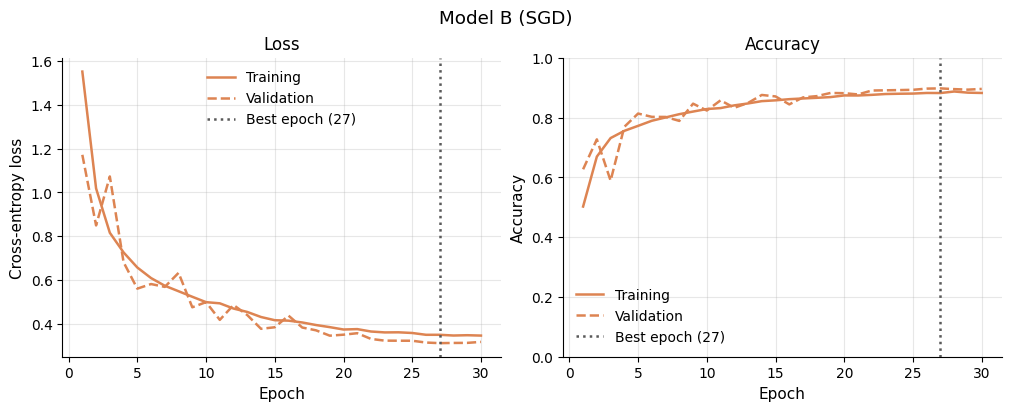

In [13]:
plot_loss_curves(histories["sgd"])

In [14]:
test_results["sgd"] = evaluate_on_test("model_b", "model_b_sgd", loaders, data.class_names)

Test accuracy 0.9025 | macro precision 0.8975 | macro recall 0.8991 | 4,050 images


## 2. SGD with momentum

Only the momentum term differs from the run above.

In [15]:
model = build_model("model_b")
histories["sgd_momentum"] = train(model, "model_b", "sgd_momentum", "model_b_sgd_momentum", loaders)

epoch  1/30  train loss 0.9525  acc 0.6601  |  val loss 0.6812  acc 0.7526  |   11.5 s  best


epoch  2/30  train loss 0.5754  acc 0.7951  |  val loss 0.4578  acc 0.8360  |   11.5 s  best


epoch  3/30  train loss 0.4614  acc 0.8374  |  val loss 0.4127  acc 0.8602  |   11.4 s  best


epoch  4/30  train loss 0.3749  acc 0.8684  |  val loss 0.3047  acc 0.8983  |   11.4 s  best


epoch  5/30  train loss 0.3326  acc 0.8847  |  val loss 0.3150  acc 0.8919  |   11.4 s


...

epoch 26/30  train loss 0.1206  acc 0.9583  |  val loss 0.1103  acc 0.9590  |   11.4 s


epoch 27/30  train loss 0.1187  acc 0.9597  |  val loss 0.1076  acc 0.9602  |   11.3 s  best


epoch 28/30  train loss 0.1158  acc 0.9597  |  val loss 0.1071  acc 0.9605  |   11.4 s  best


epoch 29/30  train loss 0.1150  acc 0.9599  |  val loss 0.1070  acc 0.9625  |   11.3 s  best


epoch 30/30  train loss 0.1127  acc 0.9596  |  val loss 0.1059  acc 0.9615  |   11.3 s
Best validation accuracy 0.9625 at epoch 29; 11.4 s per epoch on cuda:0 (Tesla T4)


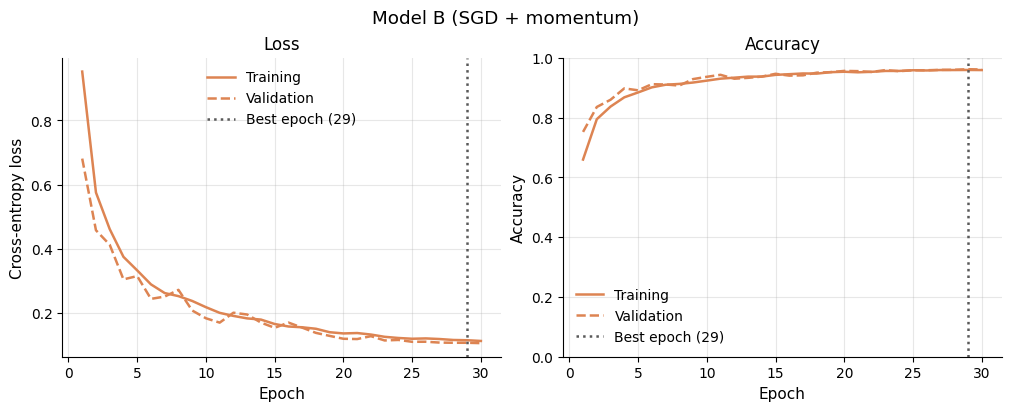

In [16]:
plot_loss_curves(histories["sgd_momentum"])

In [17]:
test_results["sgd_momentum"] = evaluate_on_test("model_b", "model_b_sgd_momentum", loaders,
                                                data.class_names)

Test accuracy 0.9632 | macro precision 0.9624 | macro recall 0.9621 | 4,050 images


## 3. Adam

This run is Model B's result for the rest of the study.

In [18]:
model = build_model("model_b")
histories["adam"] = train(model, "model_b", "adam", "model_b_adam", loaders)

epoch  1/30  train loss 0.7838  acc 0.7316  |  val loss 0.5047  acc 0.8212  |   11.5 s  best


epoch  2/30  train loss 0.4691  acc 0.8386  |  val loss 0.3938  acc 0.8588  |   11.3 s  best


epoch  3/30  train loss 0.3827  acc 0.8665  |  val loss 0.3024  acc 0.9025  |   11.4 s  best


epoch  4/30  train loss 0.3322  acc 0.8847  |  val loss 0.2896  acc 0.8975  |   11.4 s


epoch  5/30  train loss 0.2998  acc 0.8963  |  val loss 0.2882  acc 0.9022  |   11.4 s


...

epoch 26/30  train loss 0.1106  acc 0.9605  |  val loss 0.1127  acc 0.9593  |   11.2 s


epoch 27/30  train loss 0.1100  acc 0.9642  |  val loss 0.1113  acc 0.9620  |   11.3 s  best


epoch 28/30  train loss 0.1070  acc 0.9626  |  val loss 0.1144  acc 0.9605  |   11.3 s


epoch 29/30  train loss 0.1053  acc 0.9641  |  val loss 0.1154  acc 0.9625  |   11.2 s  best


epoch 30/30  train loss 0.1038  acc 0.9636  |  val loss 0.1116  acc 0.9593  |   11.3 s
Best validation accuracy 0.9625 at epoch 29; 11.3 s per epoch on cuda:0 (Tesla T4)


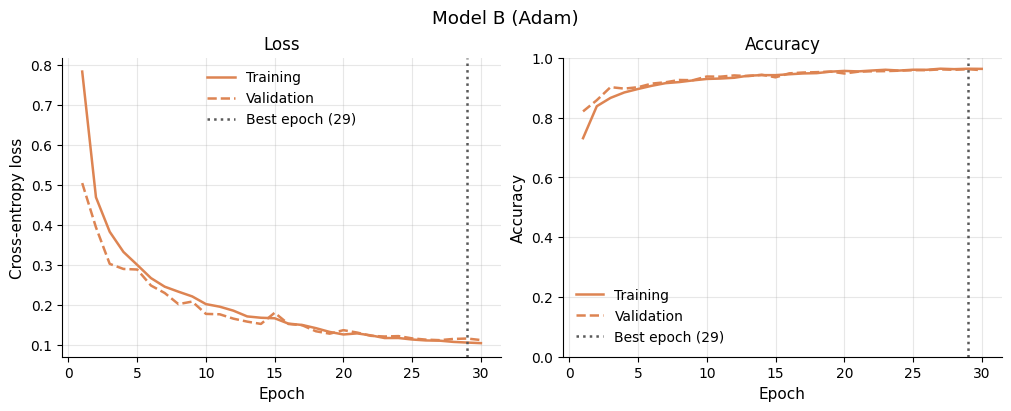

In [19]:
plot_loss_curves(histories["adam"])

In [20]:
test_results["adam"] = evaluate_on_test("model_b", "model_b_adam", loaders, data.class_names)

Test accuracy 0.9617 | macro precision 0.9608 | macro recall 0.9609 | 4,050 images


## All three on one axis

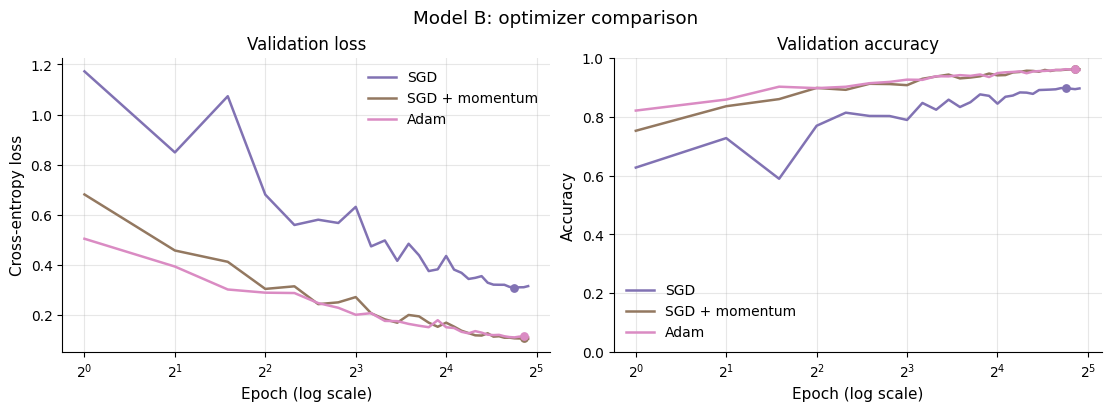

In [21]:
order = ("sgd", "sgd_momentum", "adam")
plot_optimizer_overlay([histories[name] for name in order])

## Summary

In [22]:
summary = summarize_study([histories[name] for name in order])
summary["test accuracy"] = [test_results[name]["accuracy"] for name in order]
summary

,best val accuracy,best epoch,epochs to 90% of best,final train accuracy,final val accuracy,final train - val gap,mean epoch time (s),test accuracy
SGD,0.898272,27.0,5.0,0.882963,0.896543,-0.013580,11.364935,0.902469
SGD + momentum,0.962469,29.0,4.0,0.959630,0.961481,-0.001852,11.400945,0.963210
Adam,0.962469,29.0,3.0,0.963598,0.959259,0.004339,11.303381,0.961728


## Confusion matrix of Model B with Adam

Normalised by true class, so the diagonal reads as per-class recall.

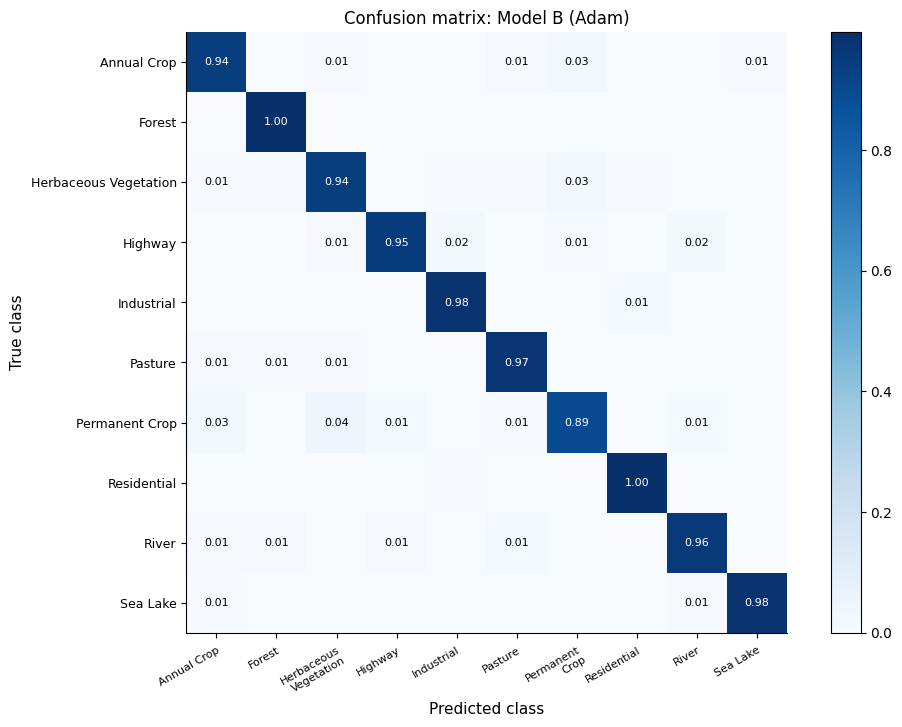

In [23]:
plot_confusion_matrix(test_results["adam"], "Model B (Adam)")